In [ ]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
data = {
     "ID":
  [ "FB01",
   "FB02",
    "FB03",
    "FB04",
    "FB05",
    "FB06" ],
   "Message":
    [ "Absolutely love the new update! Everything works perfectly.",
     "The app keeps crashing. Very frustrating experience.",
      "It's okay, but could be improved in some areas.",
      "Great customer service and fast response time!",
      "I waited 20 minutes and still no reply. Disappointed.",
      "Not sure how I feel about the new design yet." ],

     "Label":  [
       "Positive",
      "Negative",
       "Neutral",
       "Positive",
       "Negative",
       "Uncertain" ]
     }

df = pd.DataFrame(data)

df

,ID,Message,Label
0,FB01,Absolutely love the new update! Everything wor...,Positive
1,FB02,The app keeps crashing. Very frustrating exper...,Negative
2,FB03,"It's okay, but could be improved in some areas.",Neutral
3,FB04,Great customer service and fast response time!,Positive
4,FB05,I waited 20 minutes and still no reply. Disapp...,Negative
5,FB06,Not sure how I feel about the new design yet.,Uncertain


In [ ]:
print("Dataset shape:", df.shape)
print("\nDataset information:")
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())
print("\nSentiment distribution:")
print(df["Label"].value_counts())

Dataset shape: (6, 3)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   ID       6 non-null      object
 1   Message  6 non-null      object
 2   Label    6 non-null      object
dtypes: object(3)
memory usage: 276.0+ bytes
None

Missing values:
ID         0
Message    0
Label      0
dtype: int64

Sentiment distribution:
Label
Positive     2
Negative     2
Neutral      1
Uncertain    1
Name: count, dtype: int64


In [ ]:
def preprocess_text(text):
   # Convert text to lowercase
   text = text.lower()
   # Remove punctuation
   text = re.sub(r'[^​\w\s]', '', text)
   # Remove extra whitespace
   text = re.sub(r'\s+', ' ', text).strip()
   return text

df["Processed_Message"] = df["Message"].apply(preprocess_text)
df[["ID", "Message", "Processed_Message", "Label"]]

,ID,Message,Processed_Message,Label
0,FB01,Absolutely love the new update! Everything wor...,absolutely love the new update everything work...,Positive
1,FB02,The app keeps crashing. Very frustrating exper...,the app keeps crashing very frustrating experi...,Negative
2,FB03,"It's okay, but could be improved in some areas.",its okay but could be improved in some areas,Neutral
3,FB04,Great customer service and fast response time!,great customer service and fast response time,Positive
4,FB05,I waited 20 minutes and still no reply. Disapp...,i waited 20 minutes and still no reply disappo...,Negative
5,FB06,Not sure how I feel about the new design yet.,not sure how i feel about the new design yet,Uncertain


In [ ]:
positive_words = {
    "love",
    "great",
    "excellent",
    "good",
    "perfect",
    "perfectly",
    "helpful",
    "fast",
    "amazing",
    "happy"
     }

negative_words = {
    "crashing",
    "crash",
    "frustrating",
    "disappointed",
    "disappointing",
    "bad",
    "poor",
    "slow",
    "problem",
    "problems",
    "terrible"
     }

uncertain_words = {
    "not sure",
    "unsure",
    "uncertain",
    "maybe",
    "perhaps",
    "could",
    "yet"
     }

In [ ]:
def detect_sentiment(text):
  text_lower = text.lower()
  # Check for uncertainty phrases first
  if "not sure" in text_lower:
    return "Uncertain"

  # Initialize scores if not uncertain
  positive_score = 0
  negative_score = 0

  # Count positive words
  for word in positive_words:
    if re.search(r'\b' + re.escape(word) + r'\b', text_lower):
      positive_score += 1

  # Count negative words
  for word in negative_words:
    if re.search(r'\b' + re.escape(word) + r'\b', text_lower):
      negative_score += 1

  # Determine sentiment
  if positive_score > negative_score:
    return "Positive"
  elif negative_score > positive_score:
    return "Negative"
  else:
    return "Neutral"

In [ ]:
df["Predicted_Label"] = df["Processed_Message"].apply(detect_sentiment)
df[[
    "ID",
    "Message",
    "Label",
    "Predicted_Label"
    ]]

,ID,Message,Label,Predicted_Label
0,FB01,Absolutely love the new update! Everything wor...,Positive,Positive
1,FB02,The app keeps crashing. Very frustrating exper...,Negative,Negative
2,FB03,"It's okay, but could be improved in some areas.",Neutral,Neutral
3,FB04,Great customer service and fast response time!,Positive,Positive
4,FB05,I waited 20 minutes and still no reply. Disapp...,Negative,Negative
5,FB06,Not sure how I feel about the new design yet.,Uncertain,Uncertain


In [ ]:
test_subset = df.iloc[[0, 1, 3, 4]].copy()
test_subset[[
    "ID",
    "Message",
    "Label",
    "Predicted_Label"
    ]]

,ID,Message,Label,Predicted_Label
0,FB01,Absolutely love the new update! Everything wor...,Positive,Positive
1,FB02,The app keeps crashing. Very frustrating exper...,Negative,Negative
3,FB04,Great customer service and fast response time!,Positive,Positive
4,FB05,I waited 20 minutes and still no reply. Disapp...,Negative,Negative


In [ ]:
test_subset["Correct"] = (
    test_subset["Label"] == test_subset["Predicted_Label"]
    )
test_subset[[
    "ID",
    "Message",
    "Label",
    "Predicted_Label",
    "Correct"
     ]]

,ID,Message,Label,Predicted_Label,Correct
0,FB01,Absolutely love the new update! Everything wor...,Positive,Positive,True
1,FB02,The app keeps crashing. Very frustrating exper...,Negative,Negative,True
3,FB04,Great customer service and fast response time!,Positive,Positive,True
4,FB05,I waited 20 minutes and still no reply. Disapp...,Negative,Negative,True


In [ ]:
accuracy = accuracy_score(
    test_subset["Label"],
    test_subset["Predicted_Label"]
)

print(f"Accuracy on the selected subset: {accuracy * 100:.2f}%")



Accuracy on the selected subset: 100.00%


In [ ]:
print(
    classification_report(
        test_subset["Label"],
        test_subset["Predicted_Label"],
        zero_division=0
    )
)


              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00         2
    Positive       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



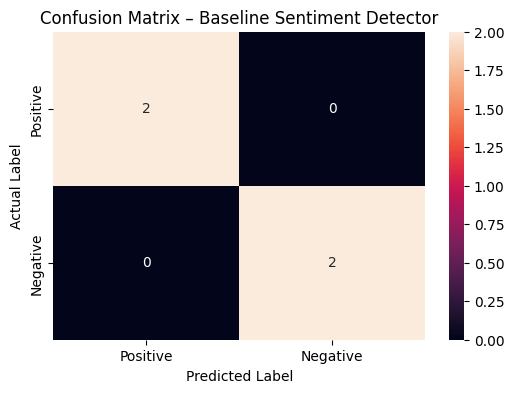

In [ ]:
labels = ["Positive", "Negative"]

cm = confusion_matrix(
    test_subset["Label"],
    test_subset["Predicted_Label"],
    labels=labels
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix – Baseline Sentiment Detector")

plt.show()


In [ ]:
results = test_subset[[
    "ID",
    "Label",
    "Predicted_Label",
    "Correct"
]]

results



,ID,Label,Predicted_Label,Correct
0,FB01,Positive,Positive,True
1,FB02,Negative,Negative,True
3,FB04,Positive,Positive,True
4,FB05,Negative,Negative,True
